데이터에 포함된 관광지 개수는 10개 입니다.
데이터에 포함된 관광지 ID 그룹은 모두 [11111111 11251813 16488201 16489518 17039715 17385794 17435963 17680713
 17759313 20019319] 입니다.
             date_time        id  gnrl  lgvh  hvvh  emvh  hndc  wmon  etc  \
9  2023-07-18 17:20:00  20019319    46     0     0     0     0     0    0   
19 2023-07-18 17:30:00  20019319    48     0     0     0     0     0    0   
29 2023-07-18 17:40:00  20019319    49     0     0     0     0     0    0   
39 2023-07-18 17:50:00  20019319    51     0     0     0     0     0    0   
49 2023-07-18 18:00:00  20019319    51     0     0     0     0     0    0   

    day_of_week  day_type  
9             1         1  
19            1         1  
29            1         1  
39            1         1  
49            1         1  


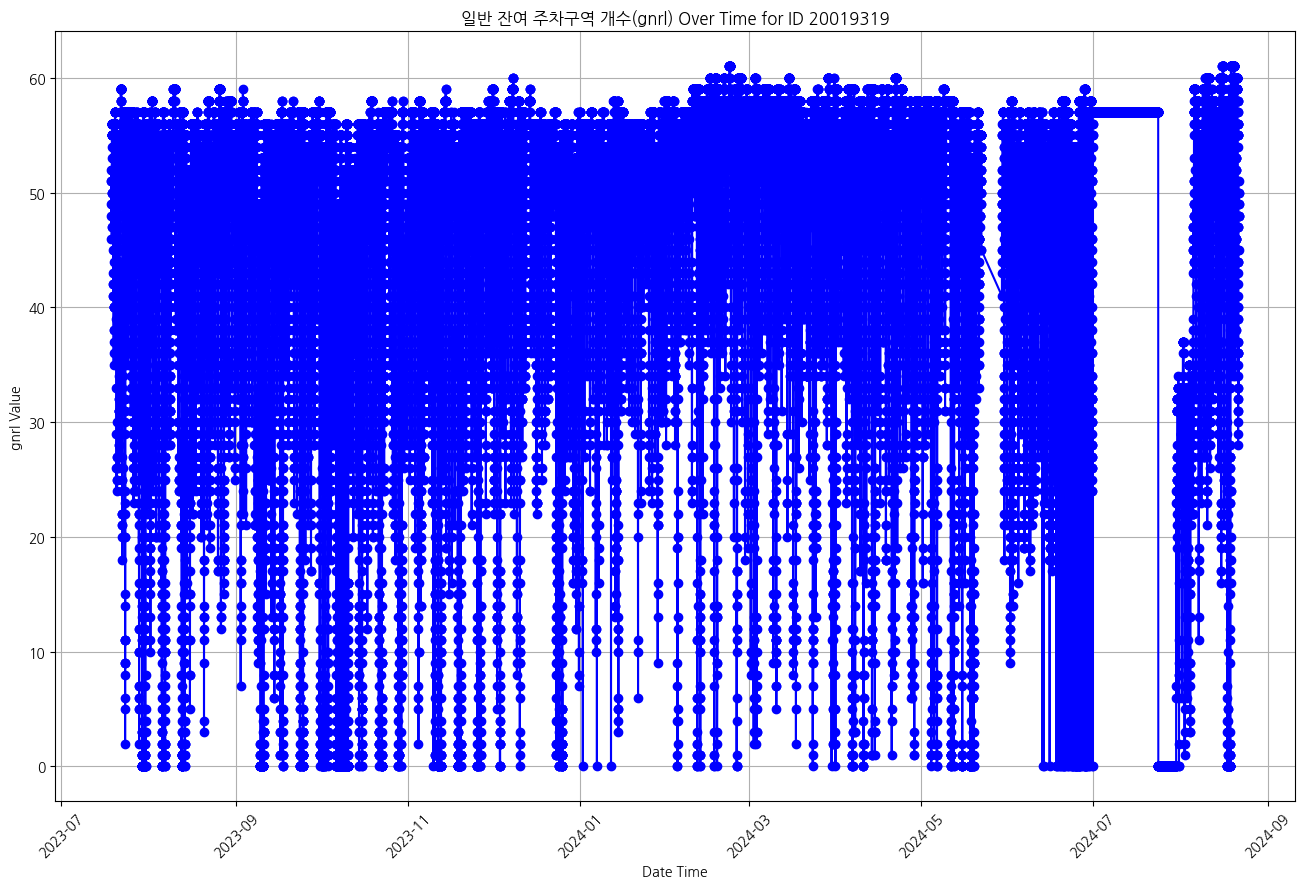

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rcParams['font.family'] = 'NanumGothic'

df = pd.read_csv('data/jeju_parking_lot_data_20230718_to_20240821.csv')

# 주차장 주차가능면수 정보
param_info = {
    'id'    :   '주차장 ID',
    'gnrl'  :   '일반 잔여 주차구역 개수',
    'lgvh'  :   '경차 잔여 주차구역 개수',
    'hvvh'  :   '대형 잔여 주차구역 개수',
    'emvh'  :   '긴급차량 잔여 주차구역 개수',
    'hndc'  :   '장애인 잔여 주차구역 개수',
    'wmon'  :   '여성전용 잔여 주차구역 개수',
    'etc'   :   '기타 잔여 주차구역 개수'
}

# 날짜 시간 데이터 변환 및 정렬
df['date_time'] = pd.to_datetime(df['date_time'])
df = df.sort_values('date_time')


# 'id'별로 데이터프레임 필터링
grouped_df = df.groupby('id')
unique_ids = df['id'].unique()

selected_id = unique_ids[9] # 접근하고 싶은 'id' 값

# 그룹의 개수 출력
print(f"데이터에 포함된 관광지 개수는 {grouped_df.ngroups}개 입니다.")

# 그룹의 id 출력
print(f"데이터에 포함된 관광지 ID 그룹은 모두 {unique_ids} 입니다.")


# 각 'id'별로 데이터프레임을 딕셔너리로 저장
id_dict = {id: group for id, group in grouped_df}

if selected_id in id_dict:
    filtered_df = id_dict[selected_id]
    print(filtered_df.head())
else:
    print(f"ID {selected_id}는 데이터에 없습니다.")

# 'date_time'에 따른 'gnrl' 그래프 그리기
plt.figure(figsize=(16, 10))
plt.plot(filtered_df['date_time'], filtered_df['gnrl'], marker='o', linestyle='-', color='blue')
plt.title(f'일반 잔여 주차구역 개수(gnrl) Over Time for ID {selected_id}')
plt.xlabel('Date Time')
plt.ylabel('gnrl Value')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_1202832/3562477469.py:27: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  train_df = filtered_df[(df['date_time'] >= start_date) & (filtered_df['date_time'] <= end_date)]


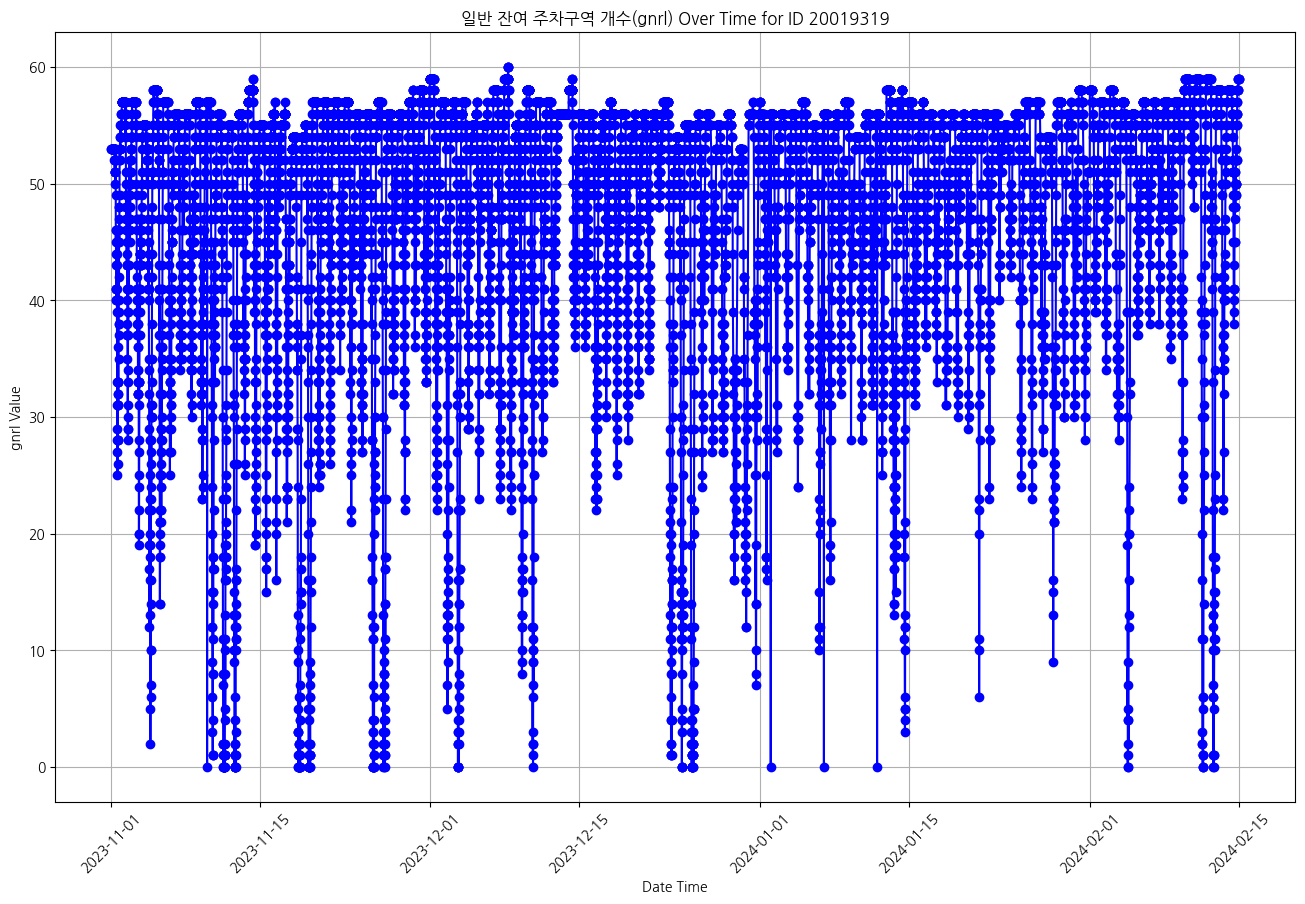

In [2]:
# 특정 기간만 필터링 - 결측치가 많아 선택적으로 학습에 활용

# 특정 기간 설정 (예: 2024-06-01부터 2024-07-25까지)

# id: 11111111, 11251813, 17759313
# start_date = '2024-06-01'
# end_date = '2024-07-25'

# id: 16488201, 17039715
# start_date = '2023-09-25'
# end_date = '2023-12-02'

# # id: 16489518
# start_date = '2023-09-15'
# end_date = '2024-02-05'


# # id: 17385794, 17435963
# start_date = '2023-11-15'
# end_date = '2024-04-30'

# id: 17680713, 20019319
start_date = '2023-11-01'
end_date = '2024-02-15'

# 조건 필터링을 사용하여 특정 기간의 데이터만 추출
train_df = filtered_df[(df['date_time'] >= start_date) & (filtered_df['date_time'] <= end_date)]

# 'date_time'에 따른 'gnrl' 그래프 그리기
plt.figure(figsize=(16, 10))
plt.plot(train_df['date_time'], train_df['gnrl'], marker='o', linestyle='-', color='blue')
plt.title(f'일반 잔여 주차구역 개수(gnrl) Over Time for ID {selected_id}')
plt.xlabel('Date Time')
plt.ylabel('gnrl Value')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

주차장: 20019319, Mean Squared Error: 37.82689859157338


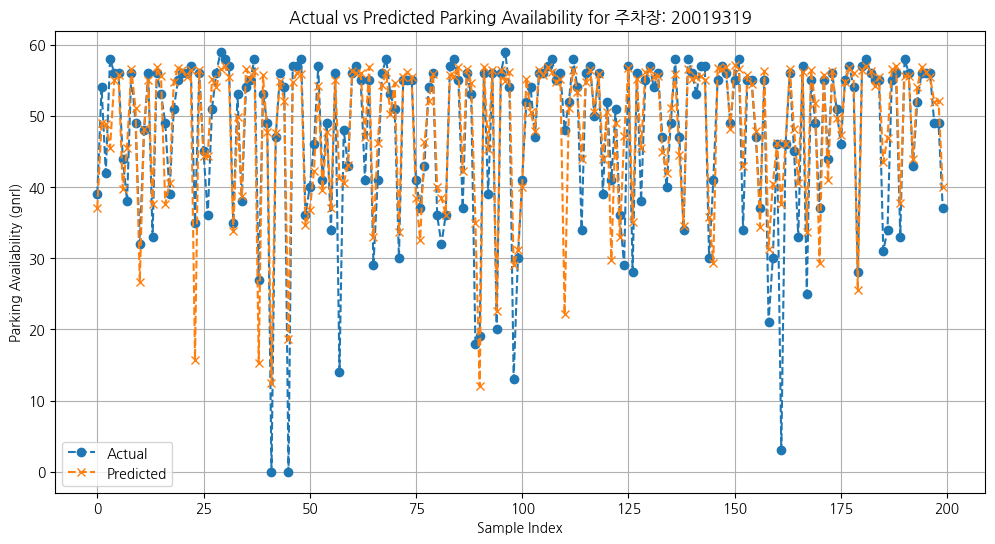

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from datetime import datetime
import numpy as np

# 시각을 'minutes_of_day'로 변환 (하루 중 경과된 분)
train_df = train_df.copy()
train_df['minutes_of_day'] = train_df['date_time'].dt.hour * 60 + train_df['date_time'].dt.minute

# 사용할 특징과 타겟 변수 설정
features = ['minutes_of_day', 'day_of_week', 'day_type']
target = 'gnrl'

# 특징과 타겟 변수 분리
X = train_df[features]
y = train_df[target]

# 훈련 및 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 정의 및 학습
model = RandomForestRegressor(n_estimators=1000, random_state=42)
model.fit(X_train, y_train)
    
# 테스트 데이터에 대한 예측
y_pred = model.predict(X_test)

# 모델 성능 평가
mse = mean_squared_error(y_test, y_pred)
model_performance = mse
print(f'주차장: {selected_id}, Mean Squared Error: {mse}')

# 그래프로 실제 데이터와 예측 데이터 비교
plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:200], label='Actual', marker='o', linestyle='dashed')
plt.plot(y_pred[:200], label='Predicted', marker='x', linestyle='dashed')
plt.title(f'Actual vs Predicted Parking Availability for 주차장: {selected_id}')
plt.xlabel('Sample Index')
plt.ylabel('Parking Availability (gnrl)')
plt.legend()
plt.grid(True)
plt.show()

                     predicted_gnrl
date_time                          
2023-12-28 00:00:00       57.211727
2023-12-28 01:00:00       56.818149
2023-12-28 02:00:00       56.709279
2023-12-28 03:00:00       56.479623
2023-12-28 04:00:00       56.565224
2023-12-28 05:00:00       57.114695
2023-12-28 06:00:00       56.598064
2023-12-28 07:00:00       56.353543
2023-12-28 08:00:00       55.588214
2023-12-28 09:00:00       51.199387
2023-12-28 10:00:00       47.806309
2023-12-28 11:00:00       39.860485
2023-12-28 12:00:00       33.807917
2023-12-28 13:00:00       32.967804
2023-12-28 14:00:00       33.805068
2023-12-28 15:00:00       40.522225
2023-12-28 16:00:00       46.825146
2023-12-28 17:00:00       47.858235
2023-12-28 18:00:00       48.168933
2023-12-28 19:00:00       48.518289
2023-12-28 20:00:00       50.743604
2023-12-28 21:00:00       53.888358
2023-12-28 22:00:00       54.723520
2023-12-28 23:00:00       56.611692
2023-12-29 00:00:00       45.827765
2023-12-29 01:00:00       56

/tmp/ipykernel_1202832/1349578086.py:60: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  fig_df = filtered_df[(df['date_time'] >= start_datetime) & (filtered_df['date_time'] <= start_datetime +timedelta(hours=48))]


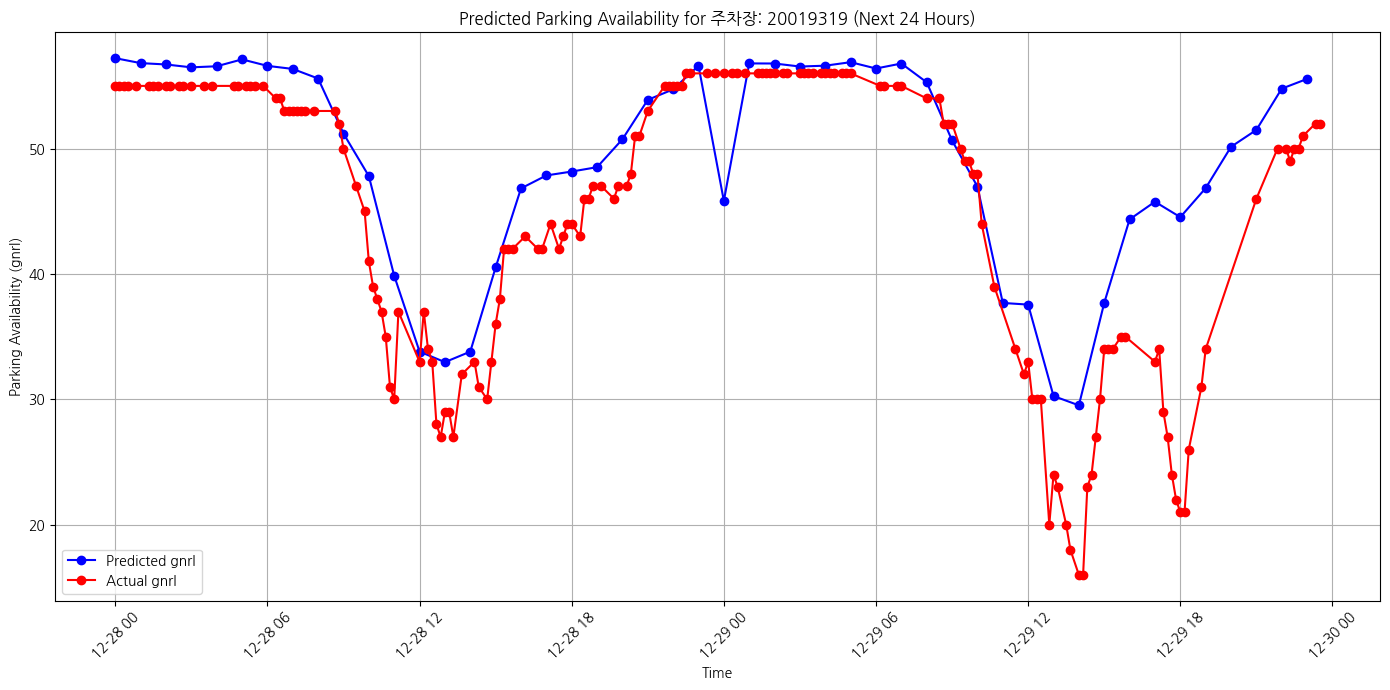

In [4]:
from datetime import datetime, timedelta
import holidays

# 미래 시각에 대한 예측 함수 정의
def predict_gnrl(date_time_str):    
    
    # 날짜 문자열을 datetime 형식으로 변환
    date_time = datetime.strptime(date_time_str, "%Y-%m-%d %H:%M:%S")
    minutes_of_day = date_time.hour * 60 + date_time.minute    

    
    day_of_week = date_time.weekday()  # 월요일이 0, 일요일이 6
    
    # 공휴일 추가
    kr_holidays = holidays.KR()  # 한국의 공휴일 정보를 가져오기

    # 평일/공휴일을 판단하는 함수
    def determine_day_type(date):
        if date in kr_holidays:
            return 0
        elif date.weekday() >= 5:  # 토요일(5) 또는 일요일(6)인 경우
            return 0
        else:
            return 1

    day_type = determine_day_type(date_time)
    
    input_data = pd.DataFrame([[minutes_of_day, day_of_week, day_type]], columns=features)
    
    # print("input_data", input_data)
    
    predicted_gnrl = model.predict(input_data)
    
    return predicted_gnrl[0]
    
    
# 예측을 시작할 기준 시각    
current_datetime = "2023-12-28 00:00:00" 
start_datetime = datetime.strptime(current_datetime, "%Y-%m-%d %H:%M:%S")

# 48시간 동안 1시간 간격으로 예측 수행
predictions = []
for i in range(48):
    current_time = start_datetime + timedelta(hours=i)
    current_time_str = current_time.strftime("%Y-%m-%d %H:%M:%S")
    predicted_gnrl = predict_gnrl(current_time_str)
    predictions.append((current_time_str, predicted_gnrl))    


df_predictions = pd.DataFrame(predictions, columns=['date_time', 'predicted_gnrl'])   # predictions 리스트를 DataFrame으로 변환

df_predictions['date_time'] = pd.to_datetime(df_predictions['date_time'])  # date_time을 datetime 형식으로 변환

df_predictions.set_index('date_time', inplace=True)  # date_time을 인덱스로 설정

# DataFrame 확인
print(df_predictions)

# 조건 필터링을 사용하여 특정 기간의 데이터만 추출
fig_df = filtered_df[(df['date_time'] >= start_datetime) & (filtered_df['date_time'] <= start_datetime +timedelta(hours=48))]

# 그래프 시각화
plt.figure(figsize=(14, 7))
plt.plot(df_predictions.index, df_predictions['predicted_gnrl'], marker='o', linestyle='-', color='blue', label='Predicted gnrl')
plt.plot(fig_df['date_time'], fig_df['gnrl'], marker='o', linestyle='-', color='red', label='Actual gnrl')
plt.title(f'Predicted Parking Availability for 주차장: {selected_id} (Next 24 Hours)')
plt.xlabel('Time')
plt.ylabel('Parking Availability (gnrl)')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# 모델 저장
import joblib
import os

file_path = f'model/jeju_parking_lot_model_{selected_id}.pkl'

os.makedirs(os.path.dirname(file_path), exist_ok=True)

joblib.dump(model, file_path)
print(f"Model saved to {file_path}")

Model saved to model/jeju_parking_lot_model_20019319.pkl
